In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [3]:
df = pd.read_csv("uber.csv")
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [4]:
print(df.shape)
print(df.info())
print(df.isnull().sum())

(200000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB
None
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [5]:
df = df.drop(['Unnamed: 0', 'key'], axis=1)

df = df.dropna()

print(df.shape)
print(df.isnull().sum())

(199999, 7)
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64


In [6]:
df = df[df['fare_amount'] > 0]

df = df[df['passenger_count'] > 0]

print(df.shape)

(199269, 7)


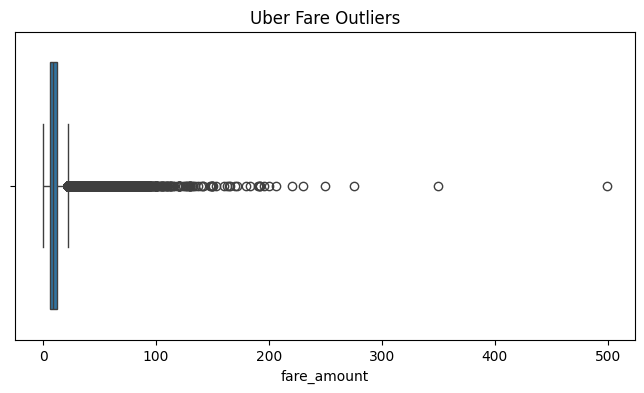

In [7]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df['fare_amount'])

plt.title("Uber Fare Outliers")
plt.show()

In [8]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

df = df[(df['fare_amount'] >= Q1 - 1.5 * IQR) &
        (df['fare_amount'] <= Q3 + 1.5 * IQR)]

print(df.shape)

(182148, 7)


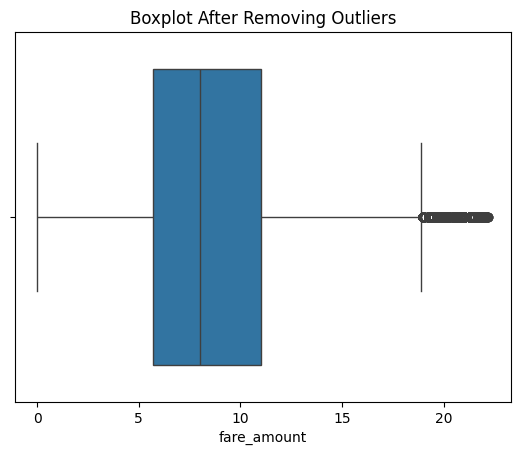

In [9]:
sns.boxplot(x=df['fare_amount'])
plt.title("Boxplot After Removing Outliers")
plt.show()

In [10]:
corr = df.select_dtypes(include='number').corr()

print(corr)

                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000          0.000125         0.002826   
pickup_longitude      0.000125          1.000000        -0.811435   
pickup_latitude       0.002826         -0.811435         1.000000   
dropoff_longitude    -0.002534          0.835878        -0.766797   
dropoff_latitude      0.000715         -0.850520         0.683972   
passenger_count       0.011995         -0.000582        -0.001742   

                   dropoff_longitude  dropoff_latitude  passenger_count  
fare_amount                -0.002534          0.000715         0.011995  
pickup_longitude            0.835878         -0.850520        -0.000582  
pickup_latitude            -0.766797          0.683972        -0.001742  
dropoff_longitude           1.000000         -0.913666         0.000271  
dropoff_latitude           -0.913666          1.000000        -0.000911  
passenger_count             0.000271         -0.000911         1.000000 

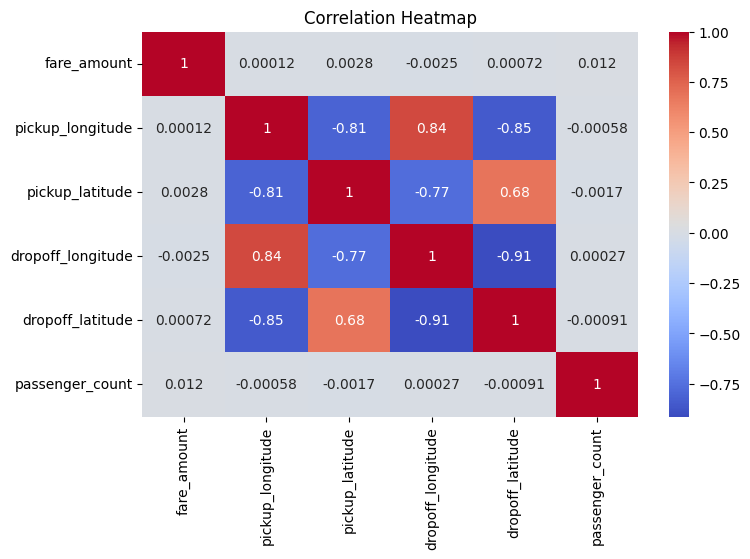

In [11]:
plt.figure(figsize=(8, 5))

sns.heatmap(corr, annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()

In [12]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month

df = df.drop('pickup_datetime', axis=1)

df.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8


In [13]:
df['distance'] = np.sqrt(
    (df['dropoff_longitude'] - df['pickup_longitude'])**2 +
    (df['dropoff_latitude'] - df['pickup_latitude'])**2
)

df.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,distance
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,0.015140
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,0.022103
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,0.053109
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,0.016528
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,0.051031


In [14]:
X = df.drop('fare_amount', axis=1)
y = df['fare_amount']

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [16]:
lr = LinearRegression()

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

In [17]:
ridge = Ridge(alpha=1)

ridge.fit(X_train, y_train)

y_pred_ridge = ridge.predict(X_test)

In [18]:
lasso = Lasso(alpha=0.1)

lasso.fit(X_train, y_train)

y_pred_lasso = lasso.predict(X_test)

In [19]:
print("Linear Regression")
print("R2:", r2_score(y_test, y_pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lr)))
print("MAE:", mean_absolute_error(y_test, y_pred_lr))

print("\nRidge Regression")
print("R2:", r2_score(y_test, y_pred_ridge))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_ridge)))
print("MAE:", mean_absolute_error(y_test, y_pred_ridge))

print("\nLasso Regression")
print("R2:", r2_score(y_test, y_pred_lasso))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lasso)))
print("MAE:", mean_absolute_error(y_test, y_pred_lasso))

Linear Regression
R2: 0.0013297727137852045
RMSE: 4.126759380291864
MAE: 3.281160826857727

Ridge Regression
R2: 0.0013297723615415258
RMSE: 4.126759381019644
MAE: 3.2811608275627924

Lasso Regression
R2: 0.0009422720416368824
RMSE: 4.127559928309901
MAE: 3.281588553472429


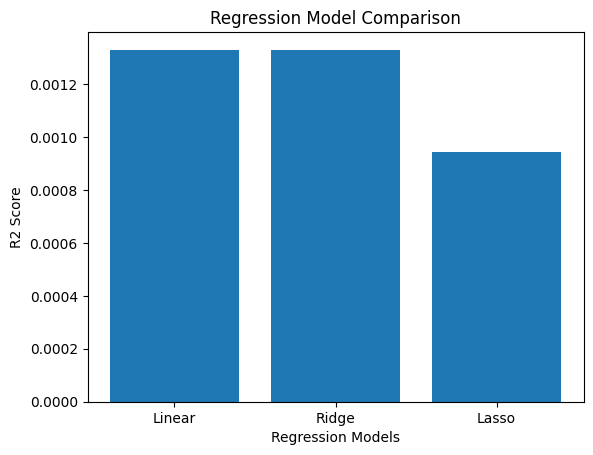

In [20]:
models = ['Linear', 'Ridge', 'Lasso']

scores = [
    r2_score(y_test, y_pred_lr),
    r2_score(y_test, y_pred_ridge),
    r2_score(y_test, y_pred_lasso)
]

plt.bar(models, scores)

plt.xlabel("Regression Models")
plt.ylabel("R2 Score")
plt.title("Regression Model Comparison")

plt.show()